# Case study: HCEA cell embedding

A cell embedding places every cell by its own chromatin contacts, with no cell
labels. This case study runs scHiCluster's embedding on 6,000 blood cells of
the Human Cell Epigenome Atlas (HCEA; snm3C-seq), 1,000 from each of six major
types: memory and naive T cells, NK, B, myeloid and mast cells. It then checks
how well the contacts alone separate the types.

| Step | epione | scHiCluster command |
|---|---|---|
| index raw contact tables | `load_contact_tables` | – |
| impute every cell at 100 kb | `impute_cells(resolution=100_000, ...)` | `hicluster impute-cell` |
| embed | `embedding(method="schicluster", norm_sig=True)` | `hicluster embedding --norm_sig` |

## 1 · Setup

In [1]:
import os
import pathlib
import warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')     # before importing epione: silences tqdm's IProgress notice
import matplotlib.pyplot as plt
import scanpy as sc

import epione as epi
from epione.single import hic

epi.pl.plot_set()

# HCEA folder with sc_contact/ and metadata/; override with EPIONE_HCEA_DIR.
DATA = pathlib.Path(os.environ.get('EPIONE_HCEA_DIR', 'data/hcea'))
FASTA = pathlib.Path(os.environ.get('EPIONE_HG38_FASTA', 'data/hg38/hg38.fa'))
OUT = pathlib.Path('result/t_sc_hic_embedding')
OUT.mkdir(parents=True, exist_ok=True)
NPROC = int(os.environ.get('EPIONE_NPROC', 16))

RES = 100_000
CHROMS = [f'chr{i}' for i in range(1, 23)]       # autosomes, as in HCEA
sizes = pd.read_csv(f'{FASTA}.fai', sep='\t', header=None, index_col=0)[1].loc[CHROMS]
files = {f.name.split('.3C.')[0]: f for f in sorted(DATA.glob('sc_contact/*/*.3C.contact.rmbkl.tsv.gz'))}
print(f'{len(files):,} contact tables')

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.

13,166 contact tables


## 2 · Cells

The HCEA summary table gives each cell's major type (`majortype`), tissue,
donor and number of long-range cis contacts. We draw 1,000 cells of each blood
type at random (`random_state=0`). Blood cells come from blood (PBMC) and from
the immune cells resident in every other tissue.

In [2]:
meta = pd.read_csv(DATA / 'metadata/5kCG100k3C_summary.csv.gz', index_col=0)
L1 = pd.read_csv(DATA / 'metadata/L1color.tsv', sep='\t', index_col=0)
meta = meta.loc[meta.index.isin(list(files))]
meta['celltype'] = meta['majortype'].map(L1['L1_abbr'])
meta = meta[meta['celltype'].str.startswith('Hema')]
N_PER_TYPE = 1000
cells = (meta.groupby('celltype', group_keys=False)
             .apply(lambda g: g.sample(min(N_PER_TYPE, len(g)), random_state=0)).index.tolist())
meta = meta.loc[cells]
TYPES = sorted(meta['celltype'].unique())
pd.crosstab(meta['Tissue'], meta['celltype'], margins=True)

celltype,Hema B,Hema Mast,Hema Myeloid,Hema NK,Hema Tmem,Hema Tnaive,All
Tissue,,,,,,,
AG,8,6,122,6,53,1,196
B,41,38,19,8,27,0,133
EG,66,189,154,41,116,0,566
LG,14,131,137,177,118,1,578
LV,1,43,104,38,26,0,212
M1C,0,0,0,6,0,2,8
NTb,1,31,100,4,22,0,158
P,0,0,0,9,0,3,12
PBMC,294,0,132,533,318,983,2260


## 3 · Raw contacts

`load_contact_tables` indexes each cell's contact table without binning it
(chromosome and position in columns 1, 2, 5 and 6, scHiCluster's layout).

In [3]:
raw = hic.load_contact_tables([files[c] for c in cells], chrom_sizes=sizes, resolution=RES,
                              cell_ids=cells, obs=meta[['celltype', 'Tissue', 'Donor', 'CisLongContact']],
                              chromosomes=CHROMS)
raw

AnnData object with n_obs × n_vars = 6000 × 0
    obs: 'contact_path', 'celltype', 'Tissue', 'Donor', 'CisLongContact'
    uns: 'hic'

## 4 · Imputation at 100 kb

`impute_cells` runs scHiCluster's `impute_chromosome` on every cell and
chromosome. scHiCluster bins the raw contacts at `resolution`, convolves them
with a 3 × 3 kernel (`pad=1`), runs a random walk with restart (`rp=0.5`,
`tol=0.01`) and normalises by square-root vanilla coverage. The call below is

```
hicluster impute-cell --pad 1 --chr1 1 --pos1 2 --chr2 5 --pos2 6 --resolution 100000 \
    --window_size 500000000 --step_size 500000000 --output_dist 1000000
```

for every cell. A 500 Mb window covers any chromosome, so the random walk runs
on whole chromosomes. The embedding reads only contacts within 1 Mb of the
diagonal, so we keep only those (`output_dist`): scHiCluster cuts at
`output_dist` after normalising, so the values kept are the same as with a
longer `output_dist`.

In [4]:
IMPUTED = OUT / 'imputed_100kb'
hic.impute_cells(raw, out_dir=IMPUTED, resolution=RES, pad=1, std=1.0, rp=0.5, tol=0.01,
                 window_size=500_000_000, step_size=500_000_000, output_dist=1_000_000,
                 compress=True, nproc=NPROC, progress=False)
print(f"{len(list(IMPUTED.glob('*.cool'))):,} imputed cells (one .cool each)")

6,000 imputed cells (one .cool each)


## 5 · Embedding

`embedding(method="schicluster")` is `hicluster embedding --dim 50 --dist
1000000 --resolution 100000 --scale_factor 100000 --norm_sig`. For each
chromosome, it takes the imputed contacts within 1 Mb of the diagonal (cells ×
pixels), multiplies them by 100,000 and reduces them to 50 components with a
truncated SVD. It then concatenates the chromosomes and reduces them again to
50 components. With `norm_sig=True`, every component is divided by its
singular value at both steps.

computing neighbors


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:10)


computing UMAP


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:07)


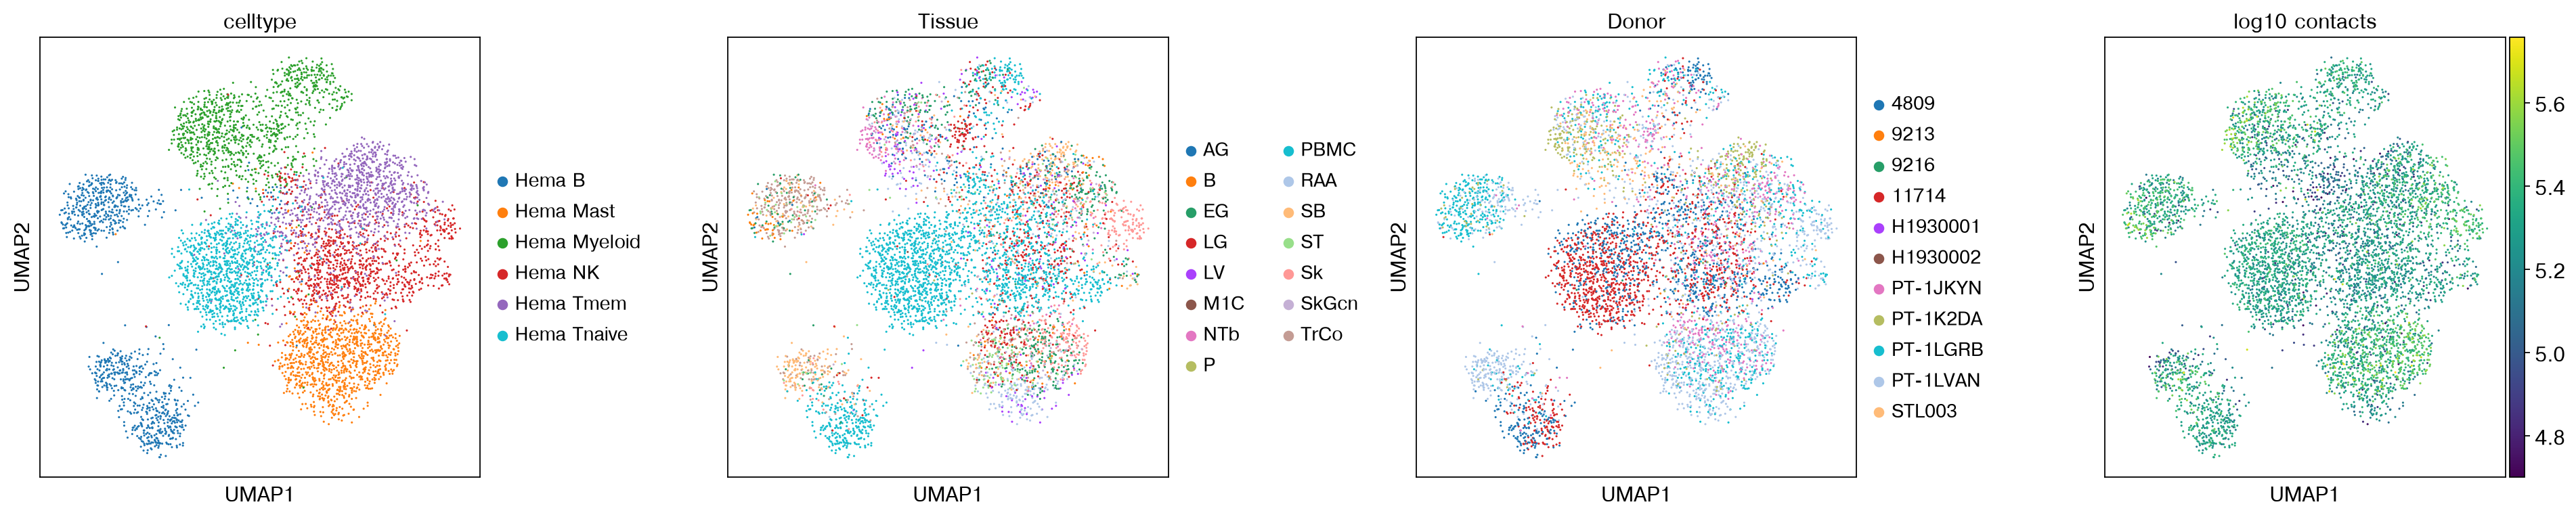

correlation of components 1-3 with log10 contacts: [-0.14 -0.16 -0.02]


In [5]:
emb = hic.embedding(raw, method='schicluster', dim=50, dist=1_000_000, scale_factor=100_000,
                    norm_sig=True)
emb.obs['celltype'] = pd.Categorical(emb.obs['celltype'], categories=TYPES)
emb.obs['log10 contacts'] = np.log10(emb.obs['CisLongContact'].astype(float))
sc.pp.neighbors(emb, n_neighbors=15, use_rep='X_schicluster')
sc.tl.umap(emb, random_state=0)
# distinct hues: six types, then up to 20 tissues / donors
palettes = {'celltype': ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#17becf'],
            'Tissue': sc.pl.palettes.default_20, 'Donor': sc.pl.palettes.default_20}
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, key in zip(axes, ['celltype', 'Tissue', 'Donor', 'log10 contacts']):
    sc.pl.umap(emb, color=key, ax=ax, show=False, title=key, size=8, palette=palettes.get(key))
plt.tight_layout(); plt.show()
X = emb.obsm['X_schicluster']
r = [np.corrcoef(X[:, k], emb.obs['log10 contacts'])[0, 1] for k in range(3)]
print('correlation of components 1-3 with log10 contacts:', np.round(r, 2))

The six types form separate groups. Naive T cells, mast cells and myeloid
cells each make one compact group, and B cells make two. Memory T and NK cells
lie next to each other and overlap. Sequencing depth barely shapes the
embedding: no component among the first three correlates with log10 contacts
beyond |r| = 0.16. Within a type, cells also group partly by tissue and donor;
this notebook applies no donor correction.

## 6 · How well do the contacts separate the types?

A cross-validated 15-nearest-neighbour classifier on the 50 components
predicts each cell's type from its neighbours. Leiden clusters on the same
neighbour graph are compared with the types by the adjusted Rand index (ARI).
The labels are used only here, never to build the embedding.

running Leiden clustering


    finished: found 6 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:02)


15-NN accuracy 0.891 (chance 0.167); Leiden: 6 clusters, ARI 0.677


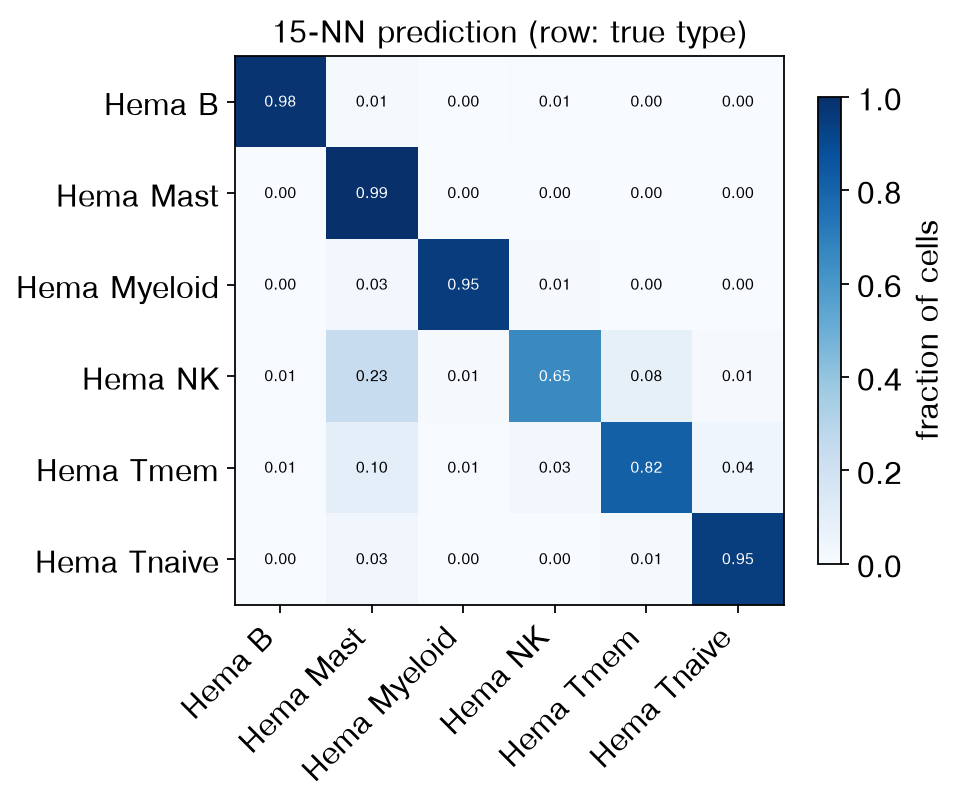

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import adjusted_rand_score
y = emb.obs['celltype'].astype(str)
pred = cross_val_predict(KNeighborsClassifier(15), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0))
sc.tl.leiden(emb, resolution=0.5, random_state=0, key_added='leiden')
print(f"15-NN accuracy {np.mean(pred == y):.3f} (chance {1 / len(TYPES):.3f}); "
      f"Leiden: {emb.obs['leiden'].nunique()} clusters, ARI {adjusted_rand_score(y, emb.obs['leiden']):.3f}")
conf = pd.crosstab(y, pd.Series(pred, index=y.index), normalize='index').loc[TYPES, TYPES]
fig, ax, img = epi.pl.plot_correlation_heatmap(conf, vmin=0, vmax=1, cmap='Blues', figsize=(5.5, 4.8),
                                               annot_fontsize=7, title='15-NN prediction (row: true type)')
fig.axes[-1].set_ylabel('fraction of cells')
plt.show()

The contacts alone predict the type of 89 % of cells (chance: 17 %), and the
six Leiden clusters agree with the types at ARI 0.68. B, mast, myeloid and
naive T cells are recovered for 95–99 % of cells. NK cells are the hardest
(65 %; 23 % are called mast cells), then memory T cells (82 %).

## Summary

| Step | epione |
|---|---|
| raw contacts | `load_contact_tables` |
| imputation, 100 kb | `impute_cells(resolution=100_000, pad=1, window_size=..., output_dist=...)` |
| embedding | `embedding(method="schicluster", norm_sig=True)` |